In [1]:
!pip install -q transformers

In [2]:
from transformers import AutoTokenizer, AutoModel
import torch

# 1. Load GPT-2 small. "eager" makes it give us the attention numbers.
tok = AutoTokenizer.from_pretrained("gpt2")
model = AutoModel.from_pretrained("gpt2", attn_implementation="eager")
model.eval()

# 2. Our test sentence
sentence = "The trophy didn't fit in the suitcase because it was too big"
inputs = tok(sentence, return_tensors="pt")
print(inputs)
# 3. See how GPT-2 split it into tokens (with their position numbers)
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])
for i, t in enumerate(tokens):
    print(i, t)

# # 4. Run the model and ask for attention
with torch.no_grad():
    out = model(**inputs, output_attentions=True)

print("Number of layers:", len(out.attentions))
print("Shape of one layer:", out.attentions[0].shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'input_ids': tensor([[  464, 16383,  1422,   470,  4197,   287,   262, 45391,   780,   340,
           373,  1165,  1263]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}
0 The
1 Ġtrophy
2 Ġdidn
3 't
4 Ġfit
5 Ġin
6 Ġthe
7 Ġsuitcase
8 Ġbecause
9 Ġit
10 Ġwas
11 Ġtoo
12 Ġbig
Number of layers: 12
Shape of one layer: torch.Size([1, 12, 13, 13])


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

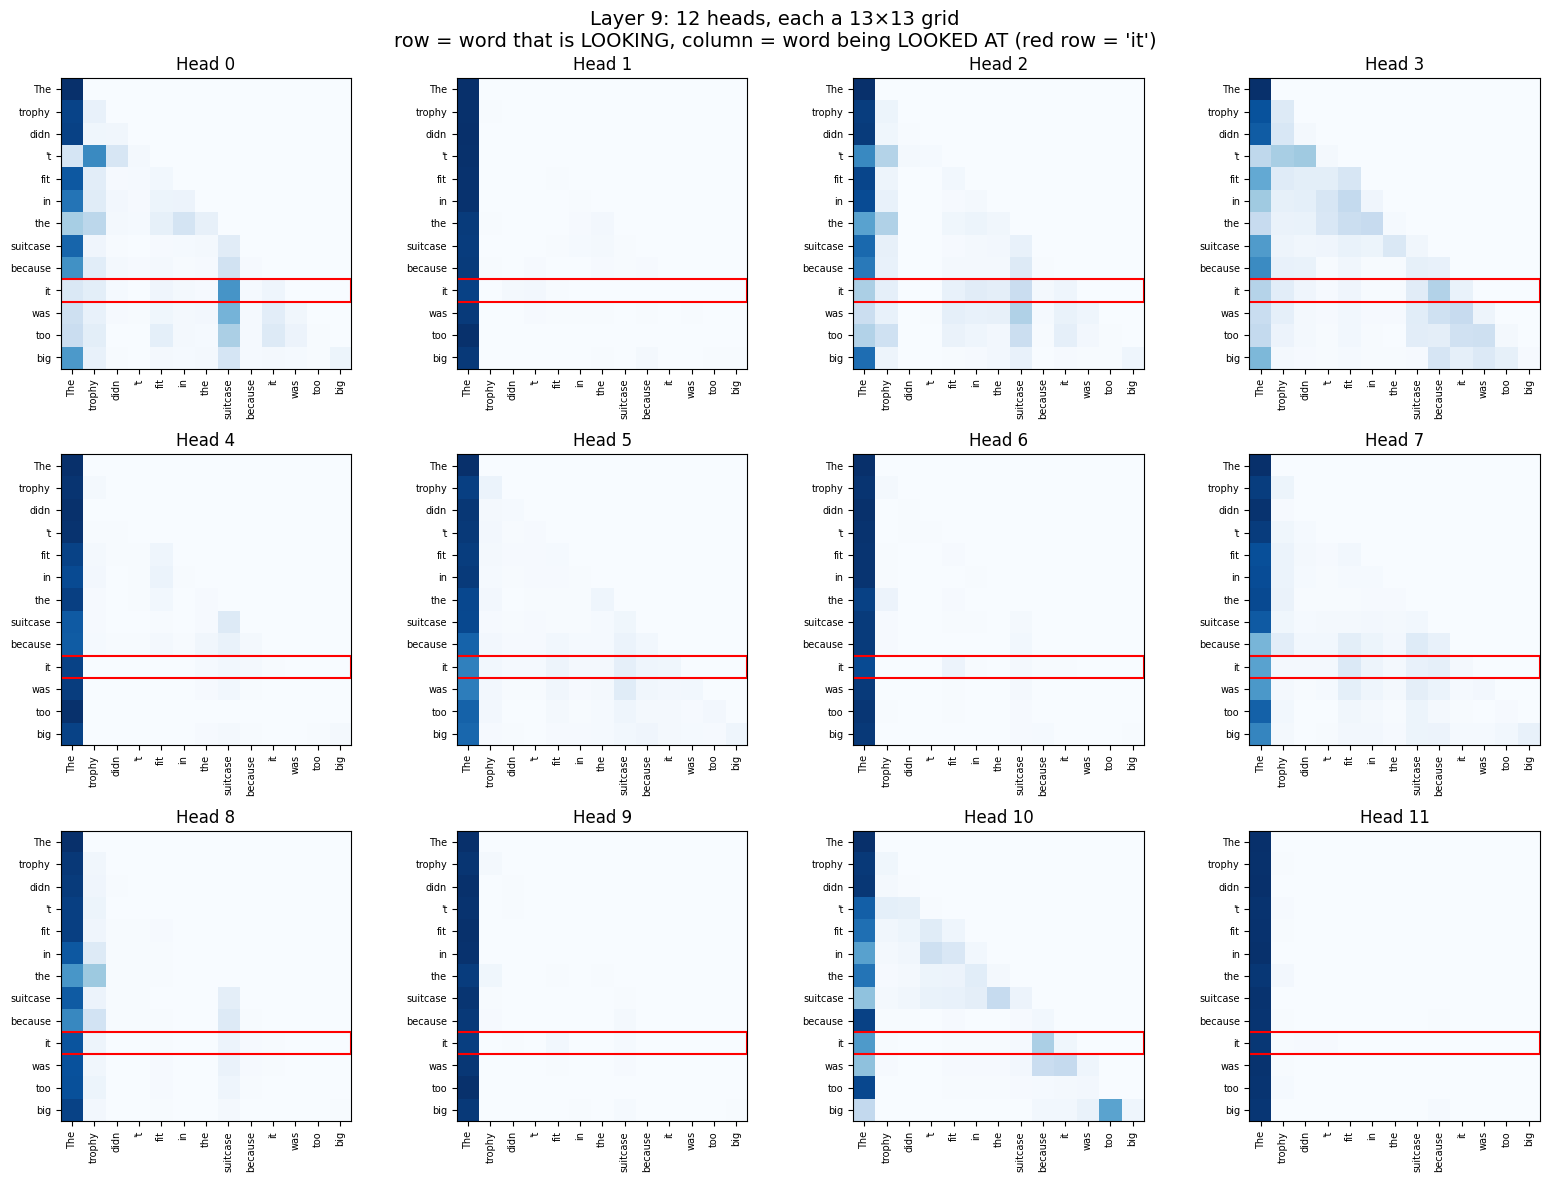

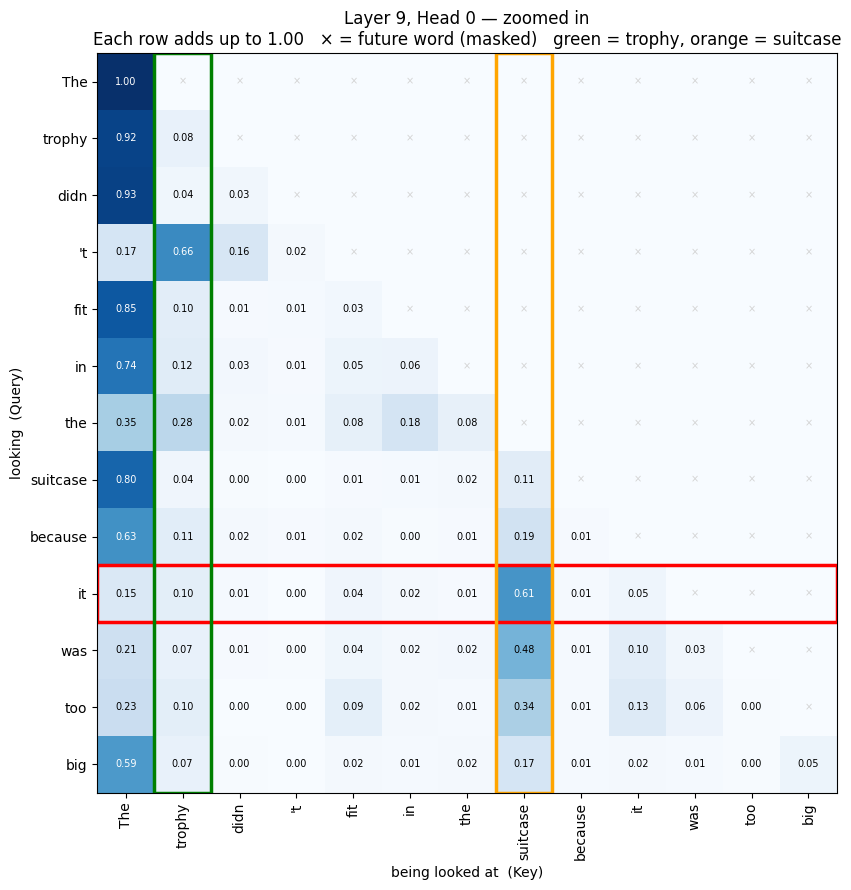

Does our hand-made attention equal GPT-2's own? True


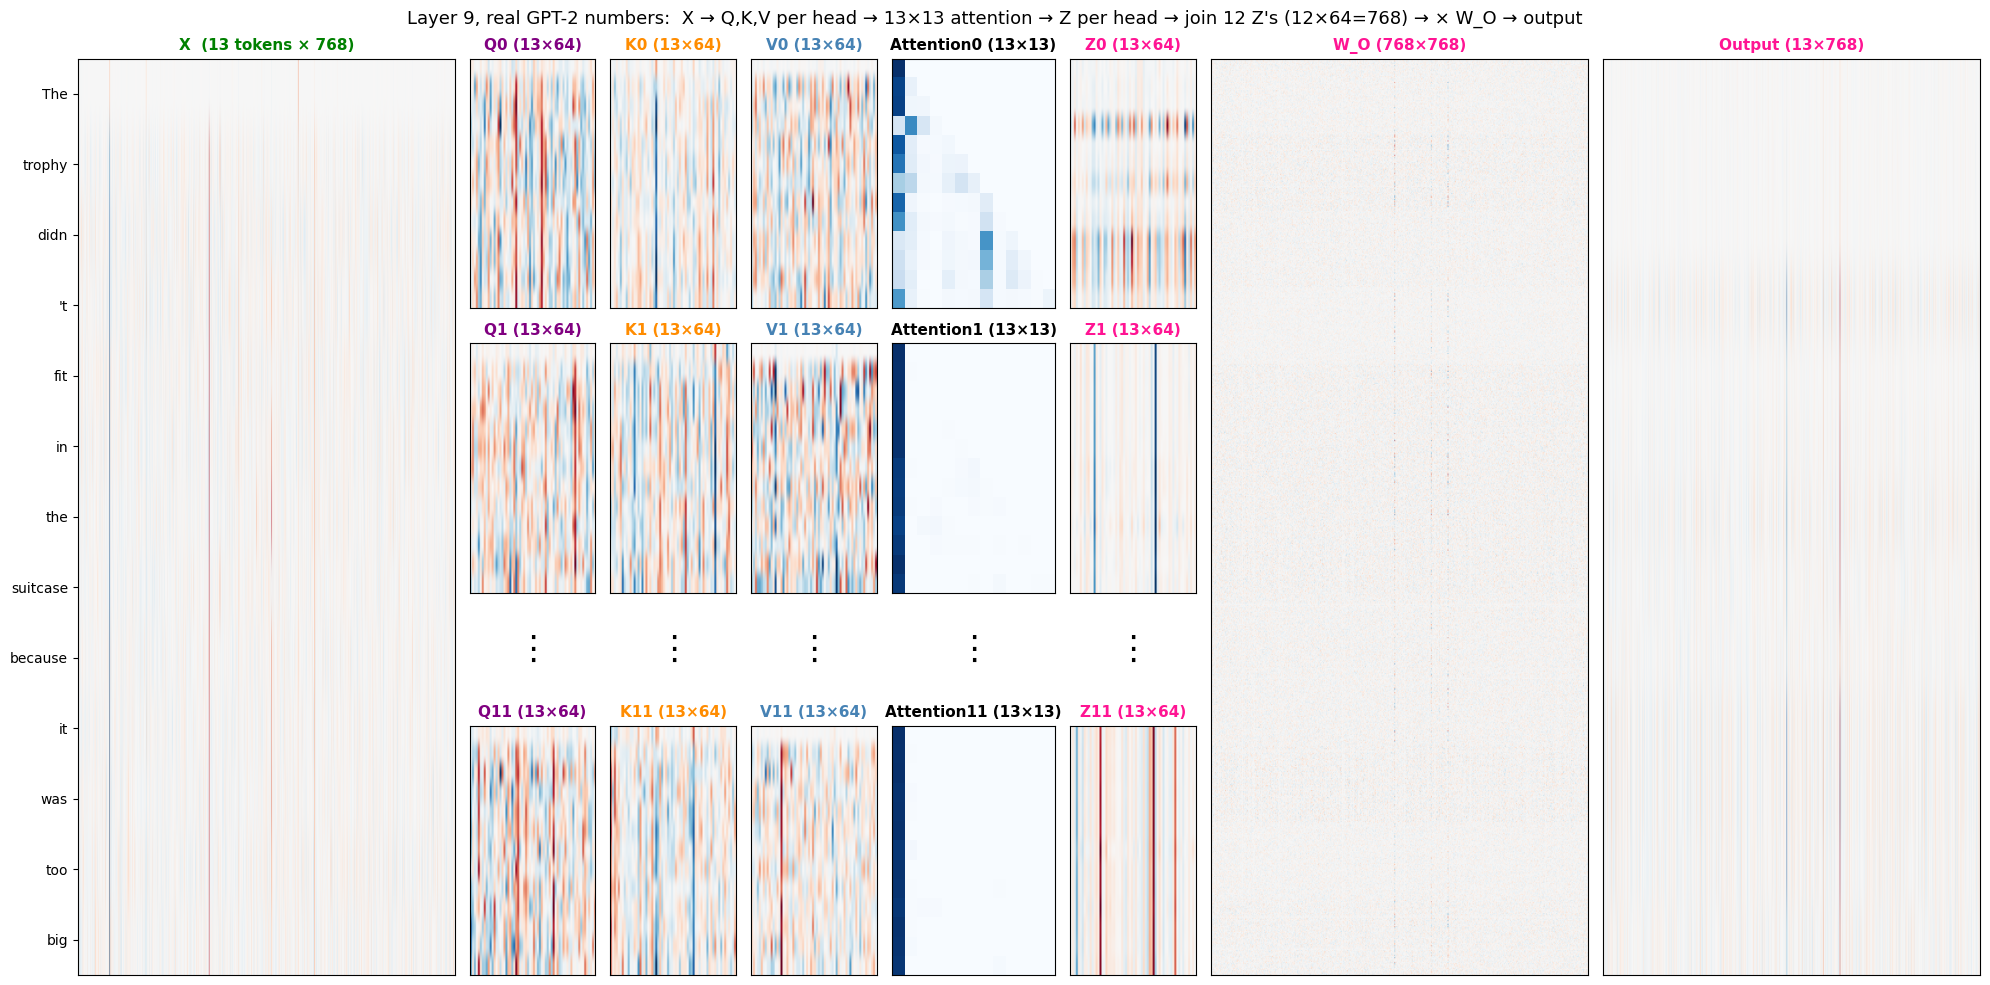

In [3]:
import torch, math
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from transformers import AutoTokenizer, AutoModel

tok = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained("gpt2", attn_implementation="eager").eval()

sentence = "The trophy didn't fit in the suitcase because it was too big"
ids = tok(sentence, return_tensors="pt")["input_ids"]
with torch.no_grad():
    out = gpt2(ids, output_attentions=True, output_hidden_states=True)

labels = [t.replace("Ġ", "") for t in tok.convert_ids_to_tokens(ids[0])]
N = len(labels)
LAYER, HEAD = 9, 0          # change these to explore other layers/heads
it_pos, trophy_pos, suitcase_pos = labels.index("it"), labels.index("trophy"), labels.index("suitcase")
att = out.attentions[LAYER][0]          # [12 heads, 13, 13]

# ── PICTURE 1: one layer = 12 heads, each a 13×13 grid ──────────────────
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for h, ax in enumerate(axes.flat):
    ax.imshow(att[h], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"Head {h}")
    ax.set_xticks(range(N)); ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(N)); ax.set_yticklabels(labels, fontsize=7)
    ax.add_patch(Rectangle((-0.5, it_pos - 0.5), N, 1, fill=False, ec="red", lw=1.5))
fig.suptitle(f"Layer {LAYER}: 12 heads, each a {N}×{N} grid\n"
             "row = word that is LOOKING, column = word being LOOKED AT (red row = 'it')", fontsize=14)
plt.tight_layout(); plt.show()

# ── PICTURE 2: zoom into one head, with the numbers ─────────────────────
grid = att[HEAD]
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(grid, cmap="Blues", vmin=0, vmax=1)
for r in range(N):
    for c in range(N):
        v = grid[r, c].item()
        ax.text(c, r, f"{v:.2f}" if c <= r else "×", ha="center", va="center",
                fontsize=7, color=("white" if v > 0.5 else "black") if c <= r else "lightgray")
ax.set_xticks(range(N)); ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(N)); ax.set_yticklabels(labels)
ax.set_xlabel("being looked at  (Key)"); ax.set_ylabel("looking  (Query)")
ax.add_patch(Rectangle((-0.5, it_pos - 0.5), N, 1, fill=False, ec="red", lw=2.5))
ax.add_patch(Rectangle((trophy_pos - 0.5, -0.5), 1, N, fill=False, ec="green", lw=2.5))
ax.add_patch(Rectangle((suitcase_pos - 0.5, -0.5), 1, N, fill=False, ec="orange", lw=2.5))
ax.set_title(f"Layer {LAYER}, Head {HEAD} — zoomed in\n"
             "Each row adds up to 1.00   × = future word (masked)   green = trophy, orange = suitcase")
plt.tight_layout(); plt.show()

# ── PICTURE 3: the full Alammar-style pipeline, real numbers ───────────
block = gpt2.h[LAYER]
with torch.no_grad():
    x = block.ln_1(out.hidden_states[LAYER][0])                  # X: 13×768
    q, k, v = block.attn.c_attn(x).split(768, dim=-1)            # X × W_Q, W_K, W_V
    q, k, v = [m.view(N, 12, 64).transpose(0, 1) for m in (q, k, v)]   # split into 12 heads
    scores = q @ k.transpose(-1, -2) / math.sqrt(64)             # Q·Kᵀ / √64
    mask = torch.triu(torch.ones(N, N, dtype=torch.bool), 1)     # hide future words
    A = scores.masked_fill(mask, float("-inf")).softmax(-1)      # 13×13 attention grid
    Z = A @ v                                                    # 13×64 per head
    concat = Z.transpose(0, 1).reshape(N, 768)                   # join 12 heads
    W_O = block.attn.c_proj.weight.detach()
    output = block.attn.c_proj(concat)                           # × W_O → 13×768

print("Does our hand-made attention equal GPT-2's own?", torch.allclose(A, att, atol=1e-4))

show = [0, 1, 11]
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(4, 8, width_ratios=[3, 1, 1, 1, 1.3, 1, 3, 3], height_ratios=[1, 1, 0.25, 1])
def panel(ax, data, title, color, cmap="RdBu_r"):
    lim = data.abs().max().item()
    ax.imshow(data, cmap=cmap, aspect="auto", vmin=(-lim if cmap == "RdBu_r" else 0), vmax=lim)
    ax.set_title(title, color=color, fontsize=11, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([])

ax = fig.add_subplot(gs[:, 0]); panel(ax, x, f"X  ({N} tokens × 768)", "green")
ax.set_yticks(range(N)); ax.set_yticklabels(labels)
for row, h in zip([0, 1, 3], show):
    panel(fig.add_subplot(gs[row, 1]), q[h], f"Q{h} ({N}×64)", "purple")
    panel(fig.add_subplot(gs[row, 2]), k[h], f"K{h} ({N}×64)", "darkorange")
    panel(fig.add_subplot(gs[row, 3]), v[h], f"V{h} ({N}×64)", "steelblue")
    panel(fig.add_subplot(gs[row, 4]), A[h], f"Attention{h} ({N}×{N})", "black", cmap="Blues")
    panel(fig.add_subplot(gs[row, 5]), Z[h], f"Z{h} ({N}×64)", "deeppink")
for col in range(1, 6):
    a = fig.add_subplot(gs[2, col]); a.axis("off"); a.text(0.5, 0.5, "⋮", ha="center", fontsize=24)
panel(fig.add_subplot(gs[:, 6]), W_O, "W_O (768×768)", "deeppink")
panel(fig.add_subplot(gs[:, 7]), output, f"Output ({N}×768)", "deeppink")
fig.suptitle(f"Layer {LAYER}, real GPT-2 numbers:  X → Q,K,V per head → 13×13 attention → Z per head "
             "→ join 12 Z's (12×64=768) → × W_O → output", fontsize=13)
plt.tight_layout(); plt.show()

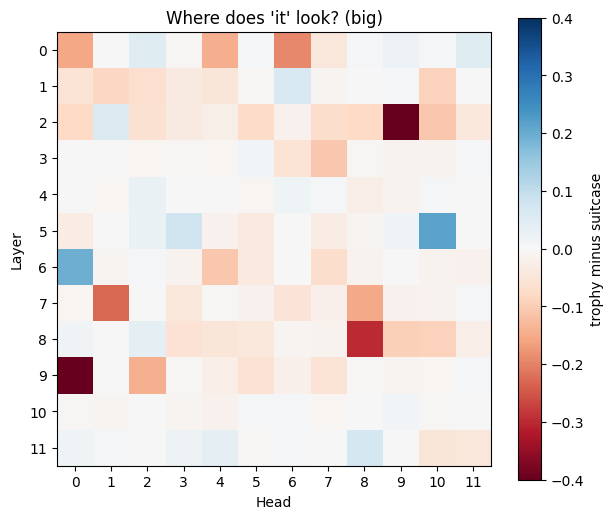

Head     trophy  suitcase  first-token
L9H0     0.10    0.61      0.15
L2H9     0.01    0.42      0.08
L0H6     0.17    0.36      0.10
L8H8     0.02    0.32      0.16
L0H0     0.13    0.29      0.22
L5H10    0.28    0.07      0.15
L7H8     0.12    0.27      0.22
L4H3     0.26    0.26      0.35
L6H0     0.26    0.06      0.45
L7H1     0.01    0.24      0.54


In [4]:
import matplotlib.pyplot as plt

# Find positions automatically (so it works for any sentence later)
def pos(word):
    return tokens.index("Ġ" + word)

it_pos, trophy_pos, suitcase_pos = pos("it"), pos("trophy"), pos("suitcase")

# Stack all 12 layers into one block: [layer, head, from_token, to_token]
att = torch.stack(out.attentions)[:, 0]

# For every head: how much does "it" look at each noun?
to_trophy   = att[:, :, it_pos, trophy_pos]     # shape [12, 12]
to_suitcase = att[:, :, it_pos, suitcase_pos]
to_first    = att[:, :, it_pos, 0]              # the "noise" sink token

# Picture: blue = prefers trophy, red = prefers suitcase
diff = to_trophy - to_suitcase
plt.figure(figsize=(7, 6))
plt.imshow(diff, cmap="RdBu", vmin=-0.4, vmax=0.4)
plt.colorbar(label="trophy minus suitcase")
plt.xlabel("Head"); plt.ylabel("Layer")
plt.title("Where does 'it' look? (big)")
plt.xticks(range(12)); plt.yticks(range(12))
plt.show()

# Top 10 heads that look at either noun the most
score = torch.maximum(to_trophy, to_suitcase)
top = torch.topk(score.flatten(), 10).indices
print("Head     trophy  suitcase  first-token")
for idx in top:
    L, H = divmod(idx.item(), 12)
    print(f"L{L}H{H:<4}  {to_trophy[L,H]:.2f}    {to_suitcase[L,H]:.2f}      {to_first[L,H]:.2f}")

Test A - biggest difference at 'it': 0.0


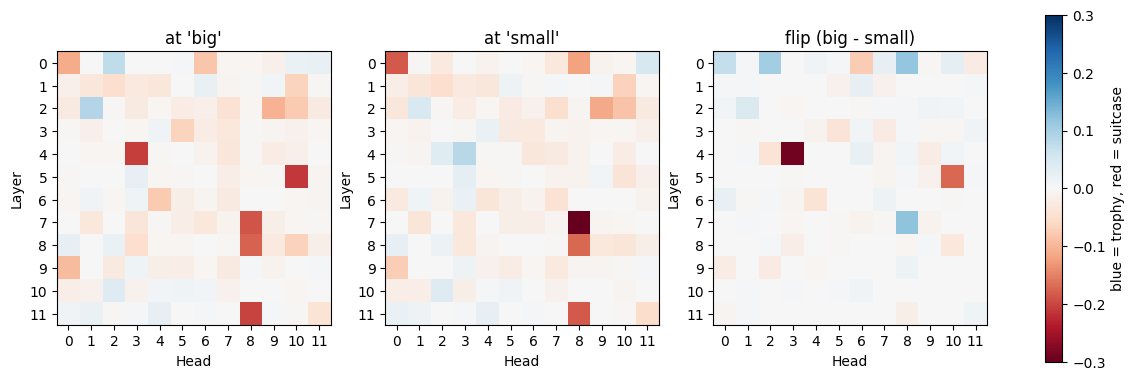


Heads that flip the CORRECT way:
L7H8: big=-0.19  small=-0.31  flip=+0.12
L0H8: big=-0.01  small=-0.12  flip=+0.12
L0H2: big=+0.08  small=-0.03  flip=+0.10
L0H0: big=-0.11  small=-0.18  flip=+0.07
L2H1: big=+0.09  small=+0.05  flip=+0.04

Heads that flip the WRONG way:
L4H3: big=-0.21  small=+0.08  flip=-0.29
L5H10: big=-0.21  small=-0.04  flip=-0.17
L0H6: big=-0.08  small=-0.01  flip=-0.08
L4H2: big=-0.01  small=+0.04  flip=-0.04
L6H4: big=-0.08  small=-0.04  flip=-0.04


In [5]:
def get_att(sentence):
    inputs = tok(sentence, return_tensors="pt")
    toks = tok.convert_ids_to_tokens(inputs["input_ids"][0])
    with torch.no_grad():
        o = model(**inputs, output_attentions=True)
    return toks, torch.stack(o.attentions)[:, 0]

def noun_pref(toks, att, from_pos):
    # positive = looks more at trophy, negative = more at suitcase
    t, s = toks.index("Ġtrophy"), toks.index("Ġsuitcase")
    return att[:, :, from_pos, t] - att[:, :, from_pos, s]

big   = "The trophy didn't fit in the suitcase because it was too big"
small = "The trophy didn't fit in the suitcase because it was too small"
tok_b, att_b = get_att(big)
tok_s, att_s = get_att(small)

# TEST A: at the word "it"
it_b = noun_pref(tok_b, att_b, tok_b.index("Ġit"))
it_s = noun_pref(tok_s, att_s, tok_s.index("Ġit"))
print("Test A - biggest difference at 'it':", round((it_b - it_s).abs().max().item(), 6))

# TEST B: at the last word ("big" / "small")
last_b = noun_pref(tok_b, att_b, len(tok_b) - 1)
last_s = noun_pref(tok_s, att_s, len(tok_s) - 1)
flip = last_b - last_s   # positive = flips the CORRECT way

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, data, title in zip(ax, [last_b, last_s, flip],
                          ["at 'big'", "at 'small'", "flip (big - small)"]):
    im = a.imshow(data, cmap="RdBu", vmin=-0.3, vmax=0.3)
    a.set_title(title); a.set_xlabel("Head"); a.set_ylabel("Layer")
    a.set_xticks(range(12)); a.set_yticks(range(12))
fig.colorbar(im, ax=ax, label="blue = trophy, red = suitcase")
plt.show()

print("\nHeads that flip the CORRECT way:")
for idx in torch.topk(flip.flatten(), 5).indices:
    L, H = divmod(idx.item(), 12)
    print(f"L{L}H{H}: big={last_b[L,H]:+.2f}  small={last_s[L,H]:+.2f}  flip={flip[L,H]:+.2f}")

print("\nHeads that flip the WRONG way:")
for idx in torch.topk(-flip.flatten(), 5).indices:
    L, H = divmod(idx.item(), 12)
    print(f"L{L}H{H}: big={last_b[L,H]:+.2f}  small={last_s[L,H]:+.2f}  flip={flip[L,H]:+.2f}")

In [6]:
from transformers import AutoModelForCausalLM
lm = AutoModelForCausalLM.from_pretrained("gpt2")
lm.eval()

def score(sentence):
    # how "natural" GPT-2 finds the sentence (higher = more likely)
    ids = tok(sentence, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        loss = lm(ids, labels=ids).loss
    return -loss.item() * (ids.shape[1] - 1)

# template, two candidates, {clue word: correct candidate}
pairs = [
    ("The trophy didn't fit in the suitcase because {} was too {}.",
     ["the trophy", "the suitcase"], {"big": "the trophy", "small": "the suitcase"}),
    ("The man couldn't lift his son because {} was so {}.",
     ["the man", "the son"], {"weak": "the man", "heavy": "the son"}),
    ("The fish ate the worm because {} was {}.",
     ["the fish", "the worm"], {"hungry": "the fish", "tasty": "the worm"}),
    ("Paul tried to call George on the phone, but {} wasn't {}.",
     ["Paul", "George"], {"successful": "Paul", "available": "George"}),
    ("The truck zoomed by the bus because {} was going so {}.",
     ["the truck", "the bus"], {"fast": "the truck", "slow": "the bus"}),
    ("The lawyer asked the witness a question, but {} was reluctant to {} it.",
     ["the lawyer", "the witness"], {"repeat": "the lawyer", "answer": "the witness"}),
]

correct = 0; total = 0
for template, cands, answers in pairs:
    for clue, right in answers.items():
        scores = {c: score(template.format(c, clue)) for c in cands}
        guess = max(scores, key=scores.get)
        ok = guess == right
        correct += ok; total += 1
        print(f"{'✅' if ok else '❌'} [{clue:>10}] GPT-2 says: {guess:<12} (correct: {right})")

print(f"\nGPT-2 got {correct}/{total} right  (random guessing = {total//2}/{total})")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


❌ [       big] GPT-2 says: the suitcase (correct: the trophy)
✅ [     small] GPT-2 says: the suitcase (correct: the suitcase)
✅ [      weak] GPT-2 says: the man      (correct: the man)
❌ [     heavy] GPT-2 says: the man      (correct: the son)
❌ [    hungry] GPT-2 says: the worm     (correct: the fish)
✅ [     tasty] GPT-2 says: the worm     (correct: the worm)
❌ [successful] GPT-2 says: George       (correct: Paul)
✅ [ available] GPT-2 says: George       (correct: George)
❌ [      fast] GPT-2 says: the bus      (correct: the truck)
✅ [      slow] GPT-2 says: the bus      (correct: the bus)
❌ [    repeat] GPT-2 says: the witness  (correct: the lawyer)
✅ [    answer] GPT-2 says: the witness  (correct: the witness)

GPT-2 got 6/12 right  (random guessing = 6/12)


In [1]:
!pip install -q transformers
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)   # should say cuda

tok = AutoTokenizer.from_pretrained("gpt2")   # all GPT-2 sizes share one tokenizer
models = {}
for name in ["gpt2", "gpt2-xl"]:             # XL is ~6 GB, first download takes a few minutes
    models[name] = AutoModelForCausalLM.from_pretrained(
        name, attn_implementation="eager").to(device).eval()
    print("Loaded", name)

def score(model, sentence):
    ids = tok(sentence, return_tensors="pt")["input_ids"].to(device)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return -loss.item() * (ids.shape[1] - 1)

pairs = [
    ("The trophy didn't fit in the suitcase because {} was too {}.",
     ["the trophy", "the suitcase"], {"big": "the trophy", "small": "the suitcase"}),
    ("The man couldn't lift his son because {} was so {}.",
     ["the man", "the son"], {"weak": "the man", "heavy": "the son"}),
    ("The fish ate the worm because {} was {}.",
     ["the fish", "the worm"], {"hungry": "the fish", "tasty": "the worm"}),
    ("Paul tried to call George on the phone, but {} wasn't {}.",
     ["Paul", "George"], {"successful": "Paul", "available": "George"}),
    ("The truck zoomed by the bus because {} was going so {}.",
     ["the truck", "the bus"], {"fast": "the truck", "slow": "the bus"}),
    ("The lawyer asked the witness a question, but {} was reluctant to {} it.",
     ["the lawyer", "the witness"], {"repeat": "the lawyer", "answer": "the witness"}),
]

solved_by = {}
for name, model in models.items():
    print(f"\n=== {name} ===")
    correct = total = uses_clue = 0
    solved_by[name] = []
    for template, cands, answers in pairs:
        guesses, oks = [], []
        for clue, right in answers.items():
            s = {c: score(model, template.format(c, clue)) for c in cands}
            g = max(s, key=s.get)
            guesses.append(g); oks.append(g == right)
            correct += g == right; total += 1
            print(f"{'✅' if g == right else '❌'} [{clue:>10}] says: {g:<12} (correct: {right})")
        if guesses[0] != guesses[1]:
            uses_clue += 1
        if all(oks):
            solved_by[name].append(template)
    print(f"→ {name}: {correct}/{total} correct | changed answer with the clue in {uses_clue}/{len(pairs)} pairs")

print("\nPairs XL fully solved (both clues right):")
for t in solved_by["gpt2-xl"]:
    print(" -", t)

Using: cuda


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Loaded gpt2-xl

=== gpt2 ===


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


❌ [       big] says: the suitcase (correct: the trophy)
✅ [     small] says: the suitcase (correct: the suitcase)
✅ [      weak] says: the man      (correct: the man)
❌ [     heavy] says: the man      (correct: the son)
❌ [    hungry] says: the worm     (correct: the fish)
✅ [     tasty] says: the worm     (correct: the worm)
❌ [successful] says: George       (correct: Paul)
✅ [ available] says: George       (correct: George)
❌ [      fast] says: the bus      (correct: the truck)
✅ [      slow] says: the bus      (correct: the bus)
❌ [    repeat] says: the witness  (correct: the lawyer)
✅ [    answer] says: the witness  (correct: the witness)
→ gpt2: 6/12 correct | changed answer with the clue in 0/6 pairs

=== gpt2-xl ===
❌ [       big] says: the suitcase (correct: the trophy)
✅ [     small] says: the suitcase (correct: the suitcase)
✅ [      weak] says: the man      (correct: the man)
✅ [     heavy] says: the son      (correct: the son)
✅ [    hungry] says: the fish     (correct: the


=== gpt2: top 5 heads that flip correctly in BOTH pairs ===
L1H5:  man/son flip=+0.06   fish/worm flip=+0.11
L4H6:  man/son flip=+0.03   fish/worm flip=+0.04
L0H2:  man/son flip=+0.05   fish/worm flip=+0.02
L2H0:  man/son flip=+0.02   fish/worm flip=+0.04
L7H8:  man/son flip=+0.01   fish/worm flip=+0.03

=== gpt2-xl: top 5 heads that flip correctly in BOTH pairs ===
L20H4:  man/son flip=+0.23   fish/worm flip=+0.95
L14H24:  man/son flip=+0.24   fish/worm flip=+0.22
L17H20:  man/son flip=+0.18   fish/worm flip=+0.56
L21H17:  man/son flip=+0.15   fish/worm flip=+0.27
L21H1:  man/son flip=+0.12   fish/worm flip=+0.25


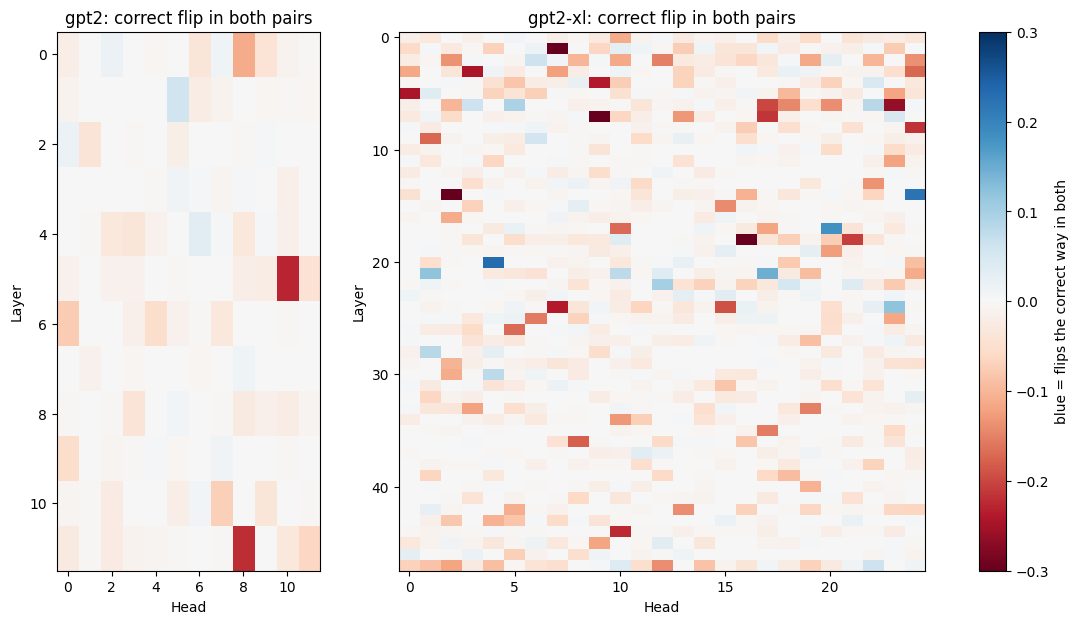

In [2]:
import matplotlib.pyplot as plt

# Original Winograd wording (with the real pronoun). First clue → first noun is correct.
attn_pairs = [
    {"sents": {"weak":  "The man couldn't lift his son because he was so weak",
               "heavy": "The man couldn't lift his son because he was so heavy"},
     "A": "man", "B": "son"},
    {"sents": {"hungry": "The fish ate the worm because it was hungry",
               "tasty":  "The fish ate the worm because it was tasty"},
     "A": "fish", "B": "worm"},
]

def pref_at_clue(model, sentence, A, B):
    # At the LAST word (the clue): does each head look more at noun A or noun B?
    ids = tok(sentence, return_tensors="pt")["input_ids"].to(device)
    toks = tok.convert_ids_to_tokens(ids[0])
    with torch.no_grad():
        o = model(ids, output_attentions=True)
    att = torch.stack(o.attentions)[:, 0].float().cpu()   # [layer, head, from, to]
    last = len(toks) - 1
    return att[:, :, last, toks.index("Ġ" + A)] - att[:, :, last, toks.index("Ġ" + B)]

results = {}
for name, model in models.items():
    flips = []
    for p in attn_pairs:
        (c1, s1), (c2, s2) = p["sents"].items()
        flips.append(pref_at_clue(model, s1, p["A"], p["B"]) - pref_at_clue(model, s2, p["A"], p["B"]))
    flips = torch.stack(flips)            # [2 pairs, layers, heads]
    both = flips.min(dim=0).values        # a head only scores high if it flips correctly in BOTH pairs
    results[name] = (flips, both)

    nh = both.shape[1]
    print(f"\n=== {name}: top 5 heads that flip correctly in BOTH pairs ===")
    for idx in torch.topk(both.flatten(), 5).indices:
        L, H = divmod(idx.item(), nh)
        print(f"L{L}H{H}:  man/son flip={flips[0,L,H]:+.2f}   fish/worm flip={flips[1,L,H]:+.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 2]})
for a, name in zip(ax, ["gpt2", "gpt2-xl"]):
    im = a.imshow(results[name][1], cmap="RdBu", vmin=-0.3, vmax=0.3, aspect="auto")
    a.set_title(f"{name}: correct flip in both pairs")
    a.set_xlabel("Head"); a.set_ylabel("Layer")
fig.colorbar(im, ax=ax, label="blue = flips the correct way in both")
plt.show()

In [3]:
import statistics as st

top_heads = [(20, 4), (14, 24), (17, 20), (21, 17), (21, 1)]   # found in Step 6
xl = models["gpt2-xl"]

# template, noun A, noun B, clue→A, clue→B, pronoun
new_pairs = [
    ("The sculpture rolled off the shelf because {} wasn't {}", "sculpture", "shelf", "anchored", "level", "it"),
    ("The table won't fit through the door because {} is too {}", "table", "door", "wide", "narrow", "it"),
    ("The knife cut the bread easily because {} was so {}", "knife", "bread", "sharp", "soft", "it"),
    ("The ball broke the window because {} was so {}", "ball", "window", "heavy", "fragile", "it"),
    ("The bag fit in the box because {} was so {}", "bag", "box", "small", "big", "it"),
    ("The lion caught the deer because {} was so {}", "lion", "deer", "fast", "slow", "it"),
    ("The car passed the bike because {} was going so {}", "car", "bike", "fast", "slow", "it"),
    ("The cat ate the mouse because {} was {}", "cat", "mouse", "hungry", "tasty", "it"),
    ("The student thanked the teacher because {} was so {}", "student", "teacher", "grateful", "helpful", "she"),
]

def xl_right(t, A, B, clue, right):
    sA = score(xl, t.format("the " + A, clue) + ".")
    sB = score(xl, t.format("the " + B, clue) + ".")
    return (sA > sB) == (right == A)

def att_last(sentence):
    ids = tok(sentence, return_tensors="pt")["input_ids"].to(device)
    toks = tok.convert_ids_to_tokens(ids[0])
    with torch.no_grad():
        o = xl(ids, output_attentions=True)
    return toks, torch.stack(o.attentions)[:, 0, :, -1, :].float().cpu()   # [layer, head, to]

print(f"{'pair':<18}{'XL':<11}" + "".join(f"L{L}H{H:<6}" for L, H in top_heads) + "all-heads avg")
rows = []
for t, A, B, cA, cB, pron in new_pairs:
    solved = xl_right(t, A, B, cA, A) and xl_right(t, A, B, cB, B)
    toks, a1 = att_last(t.format(pron, cA))
    _,    a2 = att_last(t.format(pron, cB))
    if "Ġ" + A not in toks or "Ġ" + B not in toks:
        print(f"{A}/{B}: skipped (noun split into several tokens)"); continue
    iA, iB = toks.index("Ġ" + A), toks.index("Ġ" + B)
    flip = (a1[:, :, iA] - a1[:, :, iB]) - (a2[:, :, iA] - a2[:, :, iB])
    hf = [flip[L, H].item() for L, H in top_heads]
    rows.append((solved, hf, flip.mean().item()))
    print(f"{A+'/'+B:<18}{'✅ solved' if solved else '❌ failed':<11}"
          + "".join(f"{v:+.2f}{'':<5}" for v in hf) + f"{flip.mean():+.3f}")

print()
for label, cond in [("Pairs XL SOLVED", True), ("Pairs XL FAILED", False)]:
    sel = [r for r in rows if r[0] == cond]
    if sel:
        print(f"{label} ({len(sel)}): avg flip of top-5 heads = {st.mean(sum(r[1])/5 for r in sel):+.3f}"
              f"   vs all 1200 heads = {st.mean(r[2] for r in sel):+.3f}")

pair              XL         L20H4     L14H24    L17H20    L21H17    L21H1     all-heads avg
sculpture/shelf   ❌ failed   +0.12     +0.05     +0.22     -0.12     -0.06     -0.004
table/door        ❌ failed   +0.29     +0.01     +0.12     -0.02     +0.01     +0.002
knife/bread       ✅ solved   +1.65     -0.42     +0.61     +0.46     +0.26     +0.024
ball/window       ❌ failed   +0.18     -0.09     +0.60     +0.54     +0.06     +0.005
bag/box           ❌ failed   -0.02     +0.18     -0.29     +0.01     -0.01     +0.001
lion/deer         ❌ failed   +0.56     -0.01     +0.18     -0.26     -0.08     +0.002
car/bike          ✅ solved   +0.21     +0.03     +0.47     +0.06     -0.03     +0.001
cat/mouse         ✅ solved   +1.03     -0.06     +0.54     +0.20     +0.31     +0.010
student/teacher   ✅ solved   +1.18     -0.12     +0.83     -0.04     +0.61     +0.007

Pairs XL SOLVED (4): avg flip of top-5 heads = +0.389   vs all 1200 heads = +0.010
Pairs XL FAILED (5): avg flip of top-5 heads = +0

In [4]:
import json
from google.colab import files

# template, noun A, noun B, clue→A, clue→B, pronoun, held_out?
all_pairs = [
    ("The trophy didn't fit in the suitcase because {} was too {}", "trophy", "suitcase", "big", "small", "it", False),
    ("The man couldn't lift his son because {} was so {}", "man", "son", "weak", "heavy", "he", False),
    ("The fish ate the worm because {} was {}", "fish", "worm", "hungry", "tasty", "it", False),
    ("The truck zoomed by the bus because {} was going so {}", "truck", "bus", "fast", "slow", "it", False),
    ("The lawyer asked the witness a question, but {} was reluctant to {} it", "lawyer", "witness", "repeat", "answer", "he", False),
    ("The sculpture rolled off the shelf because {} wasn't {}", "sculpture", "shelf", "anchored", "level", "it", True),
    ("The table won't fit through the door because {} is too {}", "table", "door", "wide", "narrow", "it", True),
    ("The knife cut the bread easily because {} was so {}", "knife", "bread", "sharp", "soft", "it", True),
    ("The ball broke the window because {} was so {}", "ball", "window", "heavy", "fragile", "it", True),
    ("The bag fit in the box because {} was so {}", "bag", "box", "small", "big", "it", True),
    ("The lion caught the deer because {} was so {}", "lion", "deer", "fast", "slow", "it", True),
    ("The car passed the bike because {} was going so {}", "car", "bike", "fast", "slow", "it", True),
    ("The cat ate the mouse because {} was {}", "cat", "mouse", "hungry", "tasty", "it", True),
    ("The student thanked the teacher because {} was so {}", "student", "teacher", "grateful", "helpful", "she", True),
]
highlight = {"gpt2": [(9, 0), (7, 8)], "gpt2-xl": [(20, 4), (17, 20), (14, 24)]}

def r(t):   # round to keep the file small
    return [[round(float(x), 3) for x in row] for row in t]

data = {"models": {}, "highlight": {m: [list(h) for h in hs] for m, hs in highlight.items()}, "pairs": []}
for name, m in models.items():
    data["models"][name] = {"layers": m.config.n_layer, "heads": m.config.n_head}

for t, A, B, cA, cB, pron, held in all_pairs:
    pair = {"template": t, "A": A, "B": B, "clues": {cA: A, cB: B}, "pronoun": pron,
            "held_out": held, "runs": {}}
    for name, m in models.items():
        pair["runs"][name] = {}
        for clue, right in [(cA, A), (cB, B)]:
            # 1) what the model answers (behaviour test)
            sA = score(m, t.format("the " + A, clue) + ".")
            sB = score(m, t.format("the " + B, clue) + ".")
            choice = A if sA > sB else B
            # 2) real attention for the pronoun sentence
            sent = t.format(pron, clue)
            ids = tok(sent, return_tensors="pt")["input_ids"].to(device)
            with torch.no_grad():
                o = m(ids, output_attentions=True)
            att = torch.stack(o.attentions)[:, 0].float().cpu()      # [layer, head, N, N]
            pair["runs"][name][clue] = {
                "sentence": sent,
                "tokens": [x.replace("Ġ", "") for x in tok.convert_ids_to_tokens(ids[0])],
                "choice": choice, "correct": choice == right,
                "last_row": [r(att[L, :, -1, :]) for L in range(att.shape[0])],   # every head, from the clue word
                "grids": {f"{L}-{H}": r(att[L, H]) for L, H in highlight[name]},  # full grid for key heads
            }
    data["pairs"].append(pair)
    print("done:", A, "/", B)

with open("attention_data.json", "w") as f:
    json.dump(data, f, separators=(",", ":"))
print("Saved. Size (MB):", round(len(json.dumps(data)) / 1e6, 1))
files.download("attention_data.json")

done: trophy / suitcase
done: man / son
done: fish / worm
done: truck / bus
done: lawyer / witness
done: sculpture / shelf
done: table / door
done: knife / bread
done: ball / window
done: bag / box
done: lion / deer
done: car / bike
done: cat / mouse
done: student / teacher
Saved. Size (MB): 3.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>